In [ ]:

!pip install nltk scikit-learn pandas matplotlib seaborn ipywidgets


In [ ]:

import nltk
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import ipywidgets as widgets
from IPython.display import display, Markdown

# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries imported successfully.")


All libraries imported successfully.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:

data = {
    "query": [

        # 1. Heart Attack Symptoms
        "What are the symptoms of a heart attack?",
        "How do I know if I am having a heart attack?",
        "Can chest pain indicate a heart attack?",
        "What are the warning signs of a cardiac attack?",
        "Does a heart attack cause sweating and breathlessness?",

        # 2. Heart Disease Risk Factors
        "What are the risk factors for heart disease?",
        "Does smoking increase the risk of heart problems?",
        "Can obesity cause cardiovascular disease?",
        "Is high cholesterol dangerous for the heart?",
        "Does family history affect heart disease risk?",

        # 3. Heart Disease Prevention
        "How can I prevent heart disease?",
        "What should I do to keep my heart healthy?",
        "How does regular exercise protect the heart?",
        "Can lifestyle changes reduce heart problems?",
        "What habits help prevent cardiovascular disease?",

        # 4. Blood Pressure Information
        "What is blood pressure?",
        "What does high blood pressure mean?",
        "Why is hypertension dangerous?",
        "What is the meaning of systolic blood pressure?",
        "How is blood pressure measured?",

        # 5. Arrhythmia Information
        "What is cardiac arrhythmia?",
        "Why does my heart beat irregularly?",
        "What causes an abnormal heart rhythm?",
        "What does an irregular heartbeat mean?",
        "Can arrhythmia affect heart function?",

        # 6. Heart Health Tests
        "What tests are used to check heart health?",
        "What is an ECG test?",
        "How does an echocardiogram work?",
        "Why is a stress test performed?",
        "What is the purpose of a cardiac blood test?",

        # 7. Heart Treatment Information
        "How is heart disease treated?",
        "What treatments are available for cardiovascular disease?",
        "Can heart disease be managed with medication?",
        "What procedures are used to treat blocked arteries?",
        "How do doctors treat heart conditions?",

        # 8. Heart Healthy Diet
        "What foods are good for heart health?",
        "What is a heart healthy diet?",
        "Should I reduce salt to protect my heart?",
        "Which foods help maintain healthy cholesterol?",
        "What should I eat to improve cardiovascular health?"
    ],

    "intent": [
        "heart_attack_symptoms"] * 5 +
        ["heart_disease_risk_factors"] * 5 +
        ["heart_disease_prevention"] * 5 +
        ["blood_pressure_info"] * 5 +
        ["arrhythmia_info"] * 5 +
        ["heart_health_tests"] * 5 +
        ["heart_treatment_info"] * 5 +
        ["heart_healthy_diet"] * 5
}

df = pd.DataFrame(data)

print("Total queries:", len(df))
print("\nIntent distribution:")
print(df["intent"].value_counts())

df.head()


Total queries: 40

Intent distribution:
intent
heart_attack_symptoms         5
heart_disease_risk_factors    5
heart_disease_prevention      5
blood_pressure_info           5
arrhythmia_info               5
heart_health_tests            5
heart_treatment_info          5
heart_healthy_diet            5
Name: count, dtype: int64


,query,intent
0,What are the symptoms of a heart attack?,heart_attack_symptoms
1,How do I know if I am having a heart attack?,heart_attack_symptoms
2,Can chest pain indicate a heart attack?,heart_attack_symptoms
3,What are the warning signs of a cardiac attack?,heart_attack_symptoms
4,Does a heart attack cause sweating and breathl...,heart_attack_symptoms


In [ ]:

knowledge_graph = [
    ("Smoking", "increases risk of", "Heart Disease"),
    ("High Cholesterol", "increases risk of", "Heart Disease"),
    ("High Blood Pressure", "increases risk of", "Heart Disease"),
    ("Exercise", "supports", "Heart Health"),
    ("Healthy Diet", "supports", "Heart Health"),
    ("Heart Attack", "involves", "Heart"),
    ("Arrhythmia", "affects", "Heart Rhythm"),
    ("ECG", "measures", "Electrical Activity"),
    ("Medication", "helps manage", "Heart Conditions"),
    ("Blood Pressure", "is measured by", "Blood Pressure Monitor"),
    ("Heart Attack", "may cause", "Chest Discomfort"),
    ("Heart Health Tests", "help assess", "Heart Function")
]

kg_df = pd.DataFrame(
    knowledge_graph,
    columns=["Concept 1", "Relationship", "Concept 2"]
)

kg_df


,Concept 1,Relationship,Concept 2
0,Smoking,increases risk of,Heart Disease
1,High Cholesterol,increases risk of,Heart Disease
2,High Blood Pressure,increases risk of,Heart Disease
3,Exercise,supports,Heart Health
4,Healthy Diet,supports,Heart Health
5,Heart Attack,involves,Heart
6,Arrhythmia,affects,Heart Rhythm
7,ECG,measures,Electrical Activity
8,Medication,helps manage,Heart Conditions
9,Blood Pressure,is measured by,Blood Pressure Monitor


In [ ]:

stop_words = set(stopwords.words("english"))

# Retain negation words because they are important in healthcare
stop_words = stop_words - {"no", "not", "nor", "never"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 5. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


# Test the function
sample = "What are the symptoms of HEART ATTACKS?"

print("Original:", sample)
print("Processed:", preprocess_text(sample))


Original: What are the symptoms of HEART ATTACKS?
Processed: symptom heart attack


In [ ]:

df["processed_query"] = df["query"].apply(preprocess_text)

df[["query", "processed_query", "intent"]].head(10)


,query,processed_query,intent
0,What are the symptoms of a heart attack?,symptom heart attack,heart_attack_symptoms
1,How do I know if I am having a heart attack?,know heart attack,heart_attack_symptoms
2,Can chest pain indicate a heart attack?,chest pain indicate heart attack,heart_attack_symptoms
3,What are the warning signs of a cardiac attack?,warning sign cardiac attack,heart_attack_symptoms
4,Does a heart attack cause sweating and breathl...,heart attack cause sweating breathlessness,heart_attack_symptoms
5,What are the risk factors for heart disease?,risk factor heart disease,heart_disease_risk_factors
6,Does smoking increase the risk of heart problems?,smoking increase risk heart problem,heart_disease_risk_factors
7,Can obesity cause cardiovascular disease?,obesity cause cardiovascular disease,heart_disease_risk_factors
8,Is high cholesterol dangerous for the heart?,high cholesterol dangerous heart,heart_disease_risk_factors
9,Does family history affect heart disease risk?,family history affect heart disease risk,heart_disease_risk_factors


In [ ]:

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(df["processed_query"])
y = df["intent"]

print("TF-IDF matrix shape:", X.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))


TF-IDF matrix shape: (40, 81)
Number of features: 81


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Training samples: 30
Testing samples: 10
Model training completed successfully!


In [ ]:

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Accuracy: 0.2
Precision: 0.1333
Recall: 0.2
F1-score: 0.15

Classification Report:
                            precision    recall  f1-score   support

           arrhythmia_info       0.00      0.00      0.00         1
       blood_pressure_info       0.00      0.00      0.00         1
     heart_attack_symptoms       1.00      1.00      1.00         1
  heart_disease_prevention       0.00      0.00      0.00         2
heart_disease_risk_factors       0.00      0.00      0.00         1
        heart_health_tests       0.33      1.00      0.50         1
        heart_healthy_diet       0.00      0.00      0.00         2
      heart_treatment_info       0.00      0.00      0.00         1

                  accuracy                           0.20        10
                 macro avg       0.17      0.25      0.19        10
              weighted avg       0.13      0.20      0.15        10



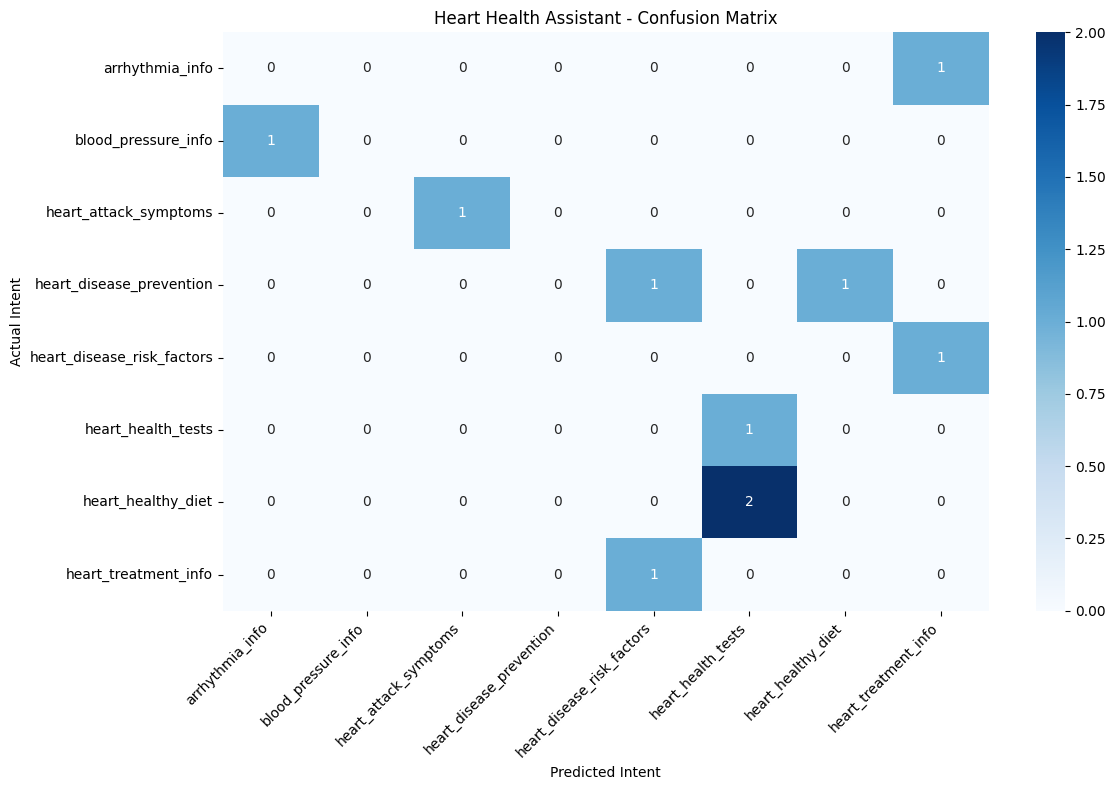

In [ ]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Health Assistant - Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [ ]:

knowledge_base = {

    "heart_attack_symptoms": """
    Heart attack symptoms may include chest discomfort, shortness
    of breath, sweating, nausea, and discomfort in the arms,
    back, neck, jaw, or stomach. Symptoms can vary among people.
    If a heart attack is suspected, contact emergency services
    immediately. Do not wait for symptoms to become severe.
    """,

    "heart_disease_risk_factors": """
    Risk factors for heart disease include high blood pressure,
    high cholesterol, smoking, diabetes, physical inactivity,
    obesity, unhealthy diet, and family history. Some risk factors
    can be modified through lifestyle changes and medical care.
    """,

    "heart_disease_prevention": """
    Heart health can be supported by regular physical activity,
    a balanced diet, avoiding tobacco, limiting excess sodium,
    maintaining a healthy weight, managing blood pressure and
    cholesterol, and following medical advice.
    """,

    "blood_pressure_info": """
    Blood pressure is the force of blood against artery walls.
    It is recorded using systolic and diastolic values.
    High blood pressure may increase cardiovascular risk.
    Regular monitoring and professional assessment are important.
    """,

    "arrhythmia_info": """
    Arrhythmia refers to an abnormal heart rhythm. It may involve
    a heartbeat that is too fast, too slow, or irregular.
    Some arrhythmias are harmless, while others require medical
    evaluation. Symptoms can include palpitations, dizziness,
    or fainting.
    """,

    "heart_health_tests": """
    Heart health may be assessed using tests such as an ECG,
    echocardiogram, blood tests, blood pressure measurement,
    and exercise stress testing. The appropriate test depends
    on the individual's symptoms and clinical situation.
    """,

    "heart_treatment_info": """
    Heart disease treatment depends on the specific condition.
    It may involve lifestyle changes, prescribed medication,
    medical procedures, or surgery. Treatment decisions must
    be made by qualified healthcare professionals.
    """,

    "heart_healthy_diet": """
    A heart-healthy eating pattern commonly emphasizes fruits,
    vegetables, whole grains, legumes, nuts, and suitable
    sources of protein. Limiting excess sodium, saturated fat,
    and highly processed foods can support cardiovascular health.
    Individual dietary needs may vary.
    """
}

print("Knowledge base created.")
print("Total intent categories:", len(knowledge_base))


Knowledge base created.
Total intent categories: 8


In [ ]:
specific_answers = {

    "What is blood pressure?":
    "Blood pressure is the force exerted by circulating blood "
    "against the walls of arteries. It is expressed using "
    "systolic and diastolic measurements.",

    "What does high blood pressure mean?":
    "High blood pressure, also called hypertension, means "
    "that the pressure of blood against artery walls is "
    "persistently elevated. It can increase cardiovascular "
    "risk and should be assessed by a healthcare professional.",

    "What is an ECG test?":
    "An electrocardiogram (ECG or EKG) records the electrical "
    "activity of the heart. It can help healthcare professionals "
    "assess heart rhythm and identify certain cardiac problems.",

    "What is cardiac arrhythmia?":
    "Cardiac arrhythmia is an abnormal heart rhythm. The "
    "heartbeat may be too fast, too slow, or irregular. "
    "Some arrhythmias require medical evaluation.",

    "What is a heart healthy diet?":
    "A heart-healthy diet generally emphasizes vegetables, "
    "fruits, whole grains, legumes, nuts, and appropriate "
    "protein sources while limiting excess sodium and "
    "saturated fat.",

    "How can I prevent heart disease?":
    "Heart disease risk may be reduced through regular "
    "physical activity, a balanced diet, avoiding tobacco, "
    "managing blood pressure and cholesterol, and following "
    "professional medical advice."
}

print("Specific answers added successfully:", len(specific_answers))

Specific answers added successfully: 6


In [ ]:

# Emergency keywords
emergency_keywords = [
    "heart attack",
    "cardiac arrest",
    "severe chest pain",
    "chest pain",
    "difficulty breathing",
    "can't breathe",
    "cannot breathe",
    "shortness of breath",
    "fainting",
    "unconscious",
    "stroke"
]

# Keywords indicating the supported heart-health domain


heart_domain_keywords = [
    "heart", "cardiac", "cardiovascular",
    "blood pressure", "cholesterol", "hypertension",
    "arrhythmia", "ecg", "echocardiogram",
    "artery", "arteries", "chest", "pulse",
    "heartbeat", "systolic", "diastolic",
    "cardiology", "heart attack", "cardiac arrest",
    "stress test", "heart disease", "blood flow",
    "heart health", "cardiovascular health",
    "palpitations", "coronary", "stent",
    "bypass", "heart rhythm", "cardiologist",
    "cardiac test", "cardiac condition"
]

def is_supported_domain(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in heart_domain_keywords
    )


def is_emergency(query):

    query = query.lower()

    for keyword in emergency_keywords:
        if keyword in query:
            return True

    return False





print(is_emergency("I think I am having a heart attack"))
print(is_supported_domain("What is blood pressure?"))


True
True


In [ ]:
def heart_health_assistant(user_query):

    # Rule 6: Empty query handling
    if not user_query or not user_query.strip():
        return "Please enter a valid heart-health question."

    query = user_query.strip()

    # Rule 1: Emergency escalation
    if is_emergency(query):
        return """
        EMERGENCY WARNING:

        Your query may indicate a medical emergency.

        If you or someone else is experiencing severe chest pain,
        possible heart attack symptoms, difficulty breathing,
        fainting, or another serious symptom, call your local
        emergency services immediately.

        In India, you can call 112 for emergency assistance.
        Do not wait for an AI response.

        This assistant cannot diagnose emergencies.
        """

    # Check for a specific predefined question
    normalized_query = query.lower().strip()

    for question, answer in specific_answers.items():
        if normalized_query == question.lower().strip():
            return f"""{answer}

            Medical Disclaimer:
            This assistant provides general educational information
            only. It does not replace professional medical advice.
            """

    # Rule 3: Unsupported domain handling
    if not is_supported_domain(query):
        return """
        I am the Heart Health Information Assistant.

        I can answer questions related to heart symptoms,
        heart disease risk factors, prevention, blood pressure,
        arrhythmia, heart tests, treatment information,
        and heart-healthy diets.

        Your query appears to be outside my supported domain.
        Please ask a heart-health-related question.
        """

    # NLP preprocessing
    processed_query = preprocess_text(query)

    # TF-IDF feature extraction
    query_vector = tfidf.transform([processed_query])

    # Intent prediction
    predicted_intent = model.predict(query_vector)[0]

    # Confidence calculation
    probabilities = model.predict_proba(query_vector)[0]
    confidence = max(probabilities)

    # Rule 2: Low-confidence handling
    if confidence < 0.40:
        return """
        I am not sufficiently confident about your question.

        Please rephrase it using clearer heart-health-related
        terms, or consult a healthcare professional.
        """

    # Rule 4: Knowledge retrieval
    response = knowledge_base.get(
        predicted_intent,
        "I do not have information for this topic."
    )

    # Rule 5: Medical safety disclaimer
    final_response = f"""
    Predicted Intent: {predicted_intent}

    Confidence: {confidence:.2f}

    Information:
    {response}

    Medical Disclaimer:
    This assistant provides general educational information
    only. It is not a medical diagnosis or a substitute for
    professional medical advice. Consult a qualified healthcare
    professional for personal medical concerns.
    """

    return final_response

In [ ]:

query = "What are the symptoms of a heart attack?"

response = heart_health_assistant(query)

print("User Query:", query)
print("\nAssistant Response:")
print(response)


User Query: What are the symptoms of a heart attack?

Assistant Response:

        EMERGENCY WARNING:

        Your query may indicate a medical emergency.

        If you or someone else is experiencing severe chest pain,
        possible heart attack symptoms, difficulty breathing,
        fainting, or another serious symptom, call your local
        emergency services immediately.

        In India, you can call 112 for emergency assistance.
        Do not wait for an AI response.

        This assistant cannot diagnose emergencies.
        


In [ ]:

# Text input
query_input = widgets.Text(
    placeholder="Ask a heart-health question...",
    description="Question:",
    layout=widgets.Layout(width="80%")
)

# Button
submit_button = widgets.Button(
    description="Ask Assistant",
    button_style="success",
    icon="heart"
)

# Output display
output_area = widgets.Output()


def on_submit_clicked(button):

    with output_area:

        output_area.clear_output()

        user_query = query_input.value

        response = heart_health_assistant(user_query)

        display(Markdown("### Assistant Response"))
        display(Markdown(response))


submit_button.on_click(on_submit_clicked)

# Display interface
display(query_input)
display(submit_button)
display(output_area)


Text(value='', description='Question:', layout=Layout(width='80%'), placeholder='Ask a heart-health question..…

Button(button_style='success', description='Ask Assistant', icon='heart', style=ButtonStyle())

Output()